In [ ]:
import numpy as np
import pandas as pd
import torch
from transformers import set_seed
import matplotlib.pyplot as plt
import json
from pathlib import Path

SEED = 42
set_seed(SEED)

train = pd.read_csv("../cleanData/train.csv")
val = pd.read_csv("../cleanData/val.csv")
test = pd.read_csv("../cleanData/test.csv")

labels = sorted(train["label"].unique())
lab2id = {l: i for i, l in enumerate(labels)}
for d in (train, val, test):
    d["y"] = d["label"].map(lab2id)

print(train["label"].value_counts(normalize=True))
print(torch.cuda.is_available())      # un GPU change complètement le temps de calcul


label
Pro    0.506842
Con    0.493158
Name: proportion, dtype: float64
False


**Contrôle du code pour s'assurer que tout soit bon**

In [15]:
import re

motifs = {
    "pro_con_debut": r"^\s*(pro|con)\s*:",      # reste d'en-tête
    "see_ref":       r"->\s*see",
    "numero_ref":    r"\[\d+\]",
    "url":           r"http\S+",
}

for nom_df, d in [("train", train), ("val", val), ("test", test)]:
    for col in ["texte_parent", "texte_enfant"]:
        for nom, motif in motifs.items():
            n = d[col].str.contains(motif, case=False, regex=True, na=False).sum()
            print(nom_df, col, nom, n)

C:\Users\Yanna\AppData\Local\Temp\ipykernel_4208\1614087966.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  n = d[col].str.contains(motif, case=False, regex=True, na=False).sum()


train texte_parent pro_con_debut 0
train texte_parent see_ref 0
train texte_parent numero_ref 0
train texte_parent url 0
train texte_enfant pro_con_debut 0
train texte_enfant see_ref 111
train texte_enfant numero_ref 0
train texte_enfant url 0
val texte_parent pro_con_debut 0
val texte_parent see_ref 0
val texte_parent numero_ref 0
val texte_parent url 0
val texte_enfant pro_con_debut 0
val texte_enfant see_ref 20
val texte_enfant numero_ref 0
val texte_enfant url 0
test texte_parent pro_con_debut 0
test texte_parent see_ref 0
test texte_parent numero_ref 0
test texte_parent url 0
test texte_enfant pro_con_debut 0
test texte_enfant see_ref 22
test texte_enfant numero_ref 0
test texte_enfant url 0


C:\Users\Yanna\AppData\Local\Temp\ipykernel_4208\1614087966.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  n = d[col].str.contains(motif, case=False, regex=True, na=False).sum()
C:\Users\Yanna\AppData\Local\Temp\ipykernel_4208\1614087966.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  n = d[col].str.contains(motif, case=False, regex=True, na=False).sum()


In [16]:
print(train.groupby("label")["texte_enfant"]
           .apply(lambda s: s.str.split().str[0].str.lower().value_counts().head(5)))

label       
Con    the      4780
       this     1398
       there    1221
       it       1051
       if       1004
Pro    the      4549
       in       1581
       a        1037
       many      828
       there     780
Name: texte_enfant, dtype: int64


In [17]:
cle = ["texte_parent", "texte_enfant"]

# doublons exacts
print("doublons train:", train.duplicated(subset=cle).sum())

# même paire, plusieurs labels
nb_labels = train.groupby(cle)["label"].nunique()
print("paires contradictoires:", (nb_labels > 1).sum())

doublons train: 333
paires contradictoires: 0


**Si il y a toujours des null, les retirer**

In [18]:
# retirer les paires contradictoires, puis les doublons
contradictoires = nb_labels[nb_labels > 1].index
train = train[~train.set_index(cle).index.isin(contradictoires)]
train = train.drop_duplicates(subset=cle)

In [19]:
def textes(d):
    return set(d["texte_enfant"])

print("train & val :", len(textes(train) & textes(val)))
print("train & test:", len(textes(train) & textes(test)))
print("val & test  :", len(textes(val) & textes(test)))

# même chose au niveau des paires
paires = lambda d: set(zip(d["texte_parent"], d["texte_enfant"]))
print("paires train & val :", len(paires(train) & paires(val)))
print("paires train & test:", len(paires(train) & paires(test)))

train & val : 34
train & test: 17
val & test  : 1
paires train & val : 10
paires train & test: 11


In [20]:
vus = textes(train)
val  = val[~val["texte_enfant"].isin(vus)]
test = test[~test["texte_enfant"].isin(vus)]

In [21]:
from sklearn.metrics import f1_score, classification_report, confusion_matrix

def evaluer(y_true, y_pred):
    return {"macro_f1": f1_score(y_true, y_pred, average="macro"), "accuracy": (y_true == y_pred).mean()}   # f1_score(..., average="macro")
# classification_report(...) donne le F1 par classe ; confusion_matrix(...) pour la figure

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack

# 1. Un vectorizer pour le parent, un pour l'enfant
vec_p = TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=10000, sublinear_tf=True)
vec_e = TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=10000, sublinear_tf=True)

# 2. fit_transform sur train, transform seulement sur val
Xp_tr = vec_p.fit_transform(train["texte_parent"])
Xe_tr = vec_e.fit_transform(train["texte_enfant"])
X_tr  = hstack([Xp_tr, Xe_tr])

X_va  = hstack([vec_p.transform(val["texte_parent"]),
                vec_e.transform(val["texte_enfant"])])

# 3. Modèle
clf = LogisticRegression(max_iter=1000, class_weight="balanced", C=10)   # class_weight="balanced" si déséquilibre
clf.fit(X_tr, train["y"])

# 4. Évaluation avec votre fonction existante
pred = clf.predict(X_va)
print(evaluer(val["y"], pred))

{'macro_f1': 0.6119503981913816, 'accuracy': np.float64(0.6133201947600279)}


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack

vec_p = TfidfVectorizer(max_features=10000)     
vec_e = TfidfVectorizer(max_features=10000)
Xp = vec_p.fit_transform(train["texte_parent"])      # fit sur le train SEULEMENT
Xe = vec_e.fit_transform(train["texte_enfant"])
X_train = hstack([Xp, Xe])
X_val = hstack([vec_p.transform(val["texte_parent"]), vec_e.transform(val["texte_enfant"])])

clf = LogisticRegression(max_iter=1000, class_weight="balanced")   # class_weight="balanced" si déséquilibre
clf.fit(X_train, train["y"])
print(evaluer(val["y"], clf.predict(X_val)))

{'macro_f1': 0.632810415845813, 'accuracy': np.float64(0.6340714120102017)}


In [24]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset

nom = "distilbert-base-uncased"       # ou "roberta-base"
tok = AutoTokenizer.from_pretrained(nom)
MAX_LEN = 128                          # issu de votre EDA (p95 ou p99 de token_paire)

def encoder(batch):
    return tok(batch["texte_parent"], batch["texte_enfant"], truncation=True, max_length=MAX_LEN)


N_TRAIN = 20000        # pour l'essai rapide ; mettez 20000 pour le premier vrai run
train_small = train.sample(n=N_TRAIN, random_state=SEED)

ds_train = Dataset.from_pandas(
    train_small[["texte_parent", "texte_enfant", "y"]].rename(columns={"y": "labels"}), preserve_index=False
).map(encoder, batched=True)


# ds_train = Dataset.from_pandas(train[["texte_parent", "texte_enfant", "y"]].rename(columns={"y": "labels"})).map(encoder, batched=True)
ds_val = Dataset.from_pandas(val[["texte_parent", "texte_enfant", "y"]].rename(columns={"y": "labels"}), preserve_index=False).map(encoder, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(nom, num_labels=len(labels))

args = TrainingArguments(output_dir="../resultats_models/checkpoints",
                        num_train_epochs=1, per_device_train_batch_size=16, learning_rate=2e-5,
                        logging_steps=50, report_to="none",
                        eval_strategy="epoch", save_strategy="epoch",
                        load_best_model_at_end=True, metric_for_best_model="macro_f1", seed=SEED)

def compute_metrics(p):
    logits = p.predictions
    if isinstance(logits, tuple):        # certains modèles renvoient un tuple, le premier élément est celui qui compte
        logits = logits[0]
    y_pred = np.argmax(logits, axis=1)   # classe prédite = indice du plus grand logit (argmax sur l'axe des classes)
    y_true = p.label_ids                 # p.label_ids
    return evaluer(y_true, y_pred)       # réutilise votre fonction : doit renvoyer un dict

trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                processing_class=tok, compute_metrics=compute_metrics)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 746.65it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [25]:
trainer.train()
pred_val = trainer.predict(ds_val)
y_pred = np.argmax(pred_val.predictions, axis=1)
print(evaluer(val["y"].values, y_pred))

c:\Users\Yanna\OneDrive\Bureau\Master\Lyon\Graph\Projet\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.587260,0.600369,0.675004,0.676096


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.10it/s]
c:\Users\Yanna\OneDrive\Bureau\Master\Lyon\Graph\Projet\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'macro_f1': 0.6750035828965759, 'accuracy': np.float64(0.6760955251565036)}


In [30]:
Path("../resultats_models").mkdir(exist_ok=True)
json.dump({"distilbert_20k_val": evaluer(val["y"].values, y_pred)}, open("../resultats_models/metrics.json", "w"))
val.assign(pred_distilbert=y_pred).to_csv("../resultats_models/pred_val.csv", index=False)

In [31]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, train["y"])
X_te = hstack([vec_p.transform(test["texte_parent"]), vec_e.transform(test["texte_enfant"])])

res = {
    "majoritaire_val":  evaluer(val["y"].values,  dummy.predict(X_val)),
    "majoritaire_test": evaluer(test["y"].values, dummy.predict(X_te)),
    "tfidf_val":        evaluer(val["y"].values,  clf.predict(X_val)),
    "tfidf_test":       evaluer(test["y"].values, clf.predict(X_te)),
}
print(res)
metrics = json.load(open("../resultats_models/metrics.json"))
metrics.update(res)
json.dump(metrics, open("../resultats_models/metrics.json", "w"))

{'majoritaire_val': {'macro_f1': 0.32400767994984525, 'accuracy': np.float64(0.479306747043821)}, 'majoritaire_test': {'macro_f1': 0.31210699670625813, 'accuracy': np.float64(0.4537144515380151)}, 'tfidf_val': {'macro_f1': 0.632810415845813, 'accuracy': np.float64(0.6340714120102017)}, 'tfidf_test': {'macro_f1': 0.6476282451854798, 'accuracy': np.float64(0.6526407428903076)}}


In [32]:
ds_test = Dataset.from_pandas(test[["texte_parent", "texte_enfant", "y"]].rename(columns={"y": "labels"}), preserve_index=False).map(encoder, batched=True)
pred_test = trainer.predict(ds_test)
y_test = np.argmax(pred_test.predictions, axis=1)

Map: 100%|██████████| 13784/13784 [00:20<00:00, 669.73 examples/s] 
c:\Users\Yanna\OneDrive\Bureau\Master\Lyon\Graph\Projet\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [33]:
Path("../figures").mkdir(exist_ok=True)

,texte_parent,texte_enfant,label
2726,Using written stories that were originally ora...,The authors of the Bible collected oral tales ...,Pro
16976,Trump escalated the conflict with North Korea ...,North Korea did not halt its nuclear weapons p...,Pro
12621,"Traditional aerial surveillance methods, such ...",Drones and helicopters are more reliable than ...,Con
4253,Not having a consistent definition of an objec...,"First, there is no consistent definition of a ...",Con
12851,Electors are pledged to vote for a candidate b...,Despite loud and powerful demands that elector...,Pro
16887,This fails to address all inconsistencies,Isaiah 7:14 says that the Messiah's name would...,Pro
7235,Women's position in society has improved such ...,People mostly believe that men and women are e...,Pro
776,Affirmative action is important to the success...,Affirmative action often puts the students it ...,Con
1995,Empirical studies of the complex processes of ...,Stephen Meyer - an American advocate of the pr...,Con
3261,"The person is the 'external force', they 'poss...","The 'external force' is not an external force,...",Pro


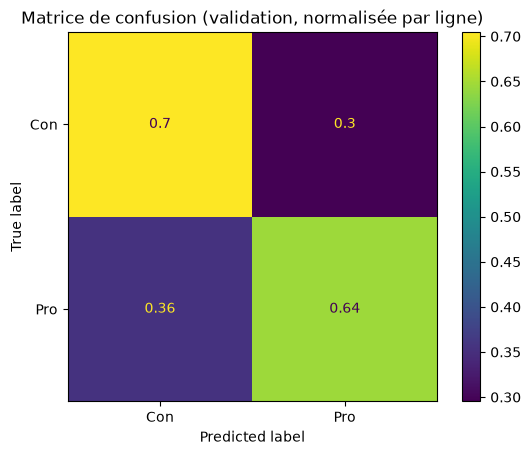

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(val["y"], y_pred, display_labels=labels, normalize="true")
plt.title("Matrice de confusion (validation, normalisée par ligne)")
plt.savefig("../figures/confusion.pdf", bbox_inches="tight")

val["pred"] = y_pred
erreurs = val[val["y"] != val["pred"]]
erreurs.sample(20, random_state=0)[["texte_parent", "texte_enfant", "label"]]

In [35]:
res_test = evaluer(test["y"].values, y_test)
print(res_test)
metrics = json.load(open("../resultats_models/metrics.json"))
metrics["distilbert_20k_test"] = res_test
metrics["distilbert_20k_test_par_classe"] = classification_report(
    test["y"], y_test, target_names=labels, output_dict=True)
json.dump(metrics, open("../resultats_models/metrics.json", "w"))
test.assign(pred_distilbert=y_test).to_csv("../resultats_models/pred_test.csv", index=False)
print(classification_report(test["y"], y_test, target_names=labels))

{'macro_f1': 0.6858304129980222, 'accuracy': np.float64(0.691526407428903)}
              precision    recall  f1-score   support

         Con       0.70      0.76      0.73      7530
         Pro       0.68      0.61      0.64      6254

    accuracy                           0.69     13784
   macro avg       0.69      0.68      0.69     13784
weighted avg       0.69      0.69      0.69     13784

